# HW2 · Part 1 — Data cleaning and validation

**Author:** Shashank Mishra · **Input:** `ohlc_hw` (dirty vendor delivery) · **Output:** `ohlc_hw_cleaned` in a *local working copy* of the database

The plan for this notebook, in the order the cells run:

1. **Inspect** the delivery (§1.1) — shape, types, ranges, ticker labels.
2. **Detect** problems (§1.2) with a small *registry of checks*. Every check has a name, a severity and a description, so adding a new rule is a single entry. The diagnosis is saved **before** anything is repaired.
3. **Clean** (§1.3) with explicit, flagged, reversible repairs; anything I cannot defend goes to a quarantine table with a reason.
4. **Validate and persist** — assertions, before/after statistics, a row-accounting identity, and the saved tables.

Two ideas drive the design. First, *evidence beats intuition*: the supplied `ohlc` table is an allowed reference, so I use it to **confirm** a fault before touching a value, rather than "fixing" anything that merely looks odd. Second, *nothing disappears silently*: every repair has a flag column and every dropped row is accounted for.

In [1]:
from __future__ import annotations

import os
import re
import shutil
import sqlite3
from contextlib import closing
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")

PRICE = ["open", "high", "low", "close"]
REL_TOL = 1e-6          # relative tolerance when comparing a price with the reference table

## 0. Where am I, and which database do I use?

The assignment says to clean a **local working copy** and to keep the source untouched. The cell below finds this homework folder, looks for a database that really contains `ohlc` and `ohlc_hw` (the repository root also holds an unrelated `data.db` with a `signals` table, so the table check matters), and copies it to `data/data.db`. That path is git-ignored, so the database can never be committed by accident. Set `HW2_SOURCE_DB` to point at a different file.

In [2]:
def locate_homework_dir() -> Path:
    """Folder that contains this notebook, even when Jupyter was started elsewhere."""
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "Homeworks" / "HW2" / "Shashank_Mishra"):
            if (candidate / "01_data_cleaning.ipynb").is_file():
                return candidate
    raise FileNotFoundError("Run from Homeworks/HW2/Shashank_Mishra (where 01_data_cleaning.ipynb lives).")


def has_tables(path: Path, *names: str) -> bool:
    """True if the SQLite file at `path` contains every named table (opened read-only)."""
    try:
        with closing(sqlite3.connect(f"{path.as_uri()}?mode=ro", uri=True)) as probe:
            found = {row[0] for row in probe.execute("SELECT name FROM sqlite_master WHERE type='table'")}
    except sqlite3.Error:
        return False
    return set(names) <= found


HW_DIR = locate_homework_dir()
REPO_ROOT = next((p for p in [HW_DIR, *HW_DIR.parents] if (p / "pyproject.toml").is_file()), HW_DIR)
WORKING_DB = HW_DIR / "data" / "data.db"

candidates = [Path(os.environ["HW2_SOURCE_DB"])] if os.environ.get("HW2_SOURCE_DB") else []
candidates += [WORKING_DB, REPO_ROOT / "Lectures/Lecture 4/data/data.db", REPO_ROOT / "data-1.db", REPO_ROOT / "data.db"]
SOURCE_DB = next((c for c in candidates if c.is_file() and has_tables(c, "ohlc", "ohlc_hw")), None)
if SOURCE_DB is None:
    raise FileNotFoundError("No database with ohlc + ohlc_hw found. Download the HW2 data.db from bCourses and set HW2_SOURCE_DB.")

WORKING_DB.parent.mkdir(parents=True, exist_ok=True)
if SOURCE_DB.resolve() != WORKING_DB.resolve():
    shutil.copy2(SOURCE_DB, WORKING_DB)
print("Homework folder :", HW_DIR.relative_to(REPO_ROOT).as_posix() if HW_DIR.is_relative_to(REPO_ROOT) else HW_DIR.name)
print("Source database :", SOURCE_DB.name, f"({SOURCE_DB.stat().st_size / 1e6:,.1f} MB)")
print("Working copy    :", WORKING_DB.relative_to(HW_DIR))

conn = sqlite3.connect(WORKING_DB)
RAW_FINGERPRINT = conn.execute("SELECT COUNT(*), SUM(volume), ROUND(SUM(close), 6) FROM ohlc_hw").fetchone()
print("ohlc_hw fingerprint (rows, sum volume, sum close):", RAW_FINGERPRINT)

Homework folder : Homeworks/HW2/Shashank_Mishra
Source database : data.db (106.4 MB)
Working copy    : data\data.db
ohlc_hw fingerprint (rows, sum volume, sum close): (397711, 12320185443562, 18411196.694811)


## 1.1 Load and inspect

`rowid AS source_rowid` is carried along so that every cleaned or quarantined row can be traced to the exact row it came from.

In [3]:
raw = pd.read_sql_query("SELECT rowid AS source_rowid, * FROM ohlc_hw", conn)
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   source_rowid  397711 non-null  int64  
 1   ts            397711 non-null  str    
 2   open          397711 non-null  float64
 3   high          397711 non-null  float64
 4   low           397711 non-null  float64
 5   close         397711 non-null  float64
 6   adj_close     377856 non-null  float64
 7   volume        397711 non-null  int64  
 8   ticker        397711 non-null  str    
dtypes: float64(5), int64(2), str(2)
memory usage: 34.7 MB


In [4]:
column_guide = pd.DataFrame(
    {"meaning": ["Row id in the source table (added by me for traceability)",
                 "Observation date (text, ISO format)",
                 "Raw open price", "Raw daily high", "Raw daily low", "Raw closing price",
                 "Vendor split/dividend-adjusted close (used for performance)",
                 "Shares traded",
                 "Vendor ticker label (may contain HTML markup)"]},
    index=["source_rowid", "ts", "open", "high", "low", "close", "adj_close", "volume", "ticker"])
display(column_guide)
display(raw.drop(columns="source_rowid").describe().T)

,meaning
source_rowid,Row id in the source table (added by me for tr...
ts,"Observation date (text, ISO format)"
open,Raw open price
high,Raw daily high
low,Raw daily low
close,Raw closing price
adj_close,Vendor split/dividend-adjusted close (used for...
volume,Shares traded
ticker,Vendor ticker label (may contain HTML markup)


,count,mean,std,min,25%,50%,75%,max
open,"397,711",46.2855,67.1326,0,4.20994,19.85,57.53,604.26
high,"397,711",46.7477,67.7782,0.005208,4.24,20.06,58.13,608.63
low,"397,711",45.8163,66.4772,0.004801,4.16,19.63,56.95,597.88
close,"397,711",46.2929,67.1419,0.005208,4.2,19.86,57.53,605.4
adj_close,"377,856",51.6523,194.584,0.00294507,1.39,11.96,43.77,"10,442.5"
volume,"397,711",3.09777e+07,1.26624e+08,0,1.7307e+06,4.6482e+06,1.10238e+07,9.27661e+09


In [5]:
print(f"Date range     : {raw['ts'].min()}  ->  {raw['ts'].max()}")
print(f"Rows           : {len(raw):,}")
print(f"Raw labels     : {raw['ticker'].nunique()} distinct strings in `ticker`")
print("Sample labels  :")
for label in raw["ticker"].drop_duplicates().sample(4, random_state=3):
    print("   ", label)
print("\nNulls per column:")
display(raw.isna().sum().to_frame("nulls").T)

Date range     : 1962-01-02  ->  2024-12-06
Rows           : 397,711
Raw labels     : 150 distinct strings in `ticker`
Sample labels  :
    <a target="_blank"><span style="font-weight: bold; color: blue">CVX</span></a>
    AAPL
    <a target="_blank"><span style="color: blue">TRV</span></a>
    MCD

Nulls per column:


,source_rowid,ts,open,high,low,close,adj_close,volume,ticker
nulls,0,0,0,0,0,0,19855,0,0


### Ticker labels first

150 label strings for what should be a few dozen stocks. Many are wrapped in HTML (`<a …><span …>NVDA</span></a>`). Grouping, de-duplicating, gap-checking and computing returns on those strings would split one stock into several series, so the labels are normalised **first**: strip tags, remove whitespace, upper-case. The original label is kept in `ticker_raw`, and the full label→ticker mapping is saved as an audit table.

In [6]:
TAG = re.compile(r"<[^>]*>")


def normalize_ticker(labels: pd.Series) -> pd.Series:
    """Remove HTML tags and whitespace, then upper-case."""
    return (labels.astype("string")
            .str.replace(TAG, "", regex=True)
            .str.replace(r"\s+", "", regex=True)
            .str.upper())


work = raw.assign(ticker_raw=raw["ticker"].astype("string"), ticker=normalize_ticker(raw["ticker"]))
assert work["ticker"].str.fullmatch(r"[A-Z][A-Z.\-]{0,5}").all(), "unexpected characters left in a ticker"
ticker_audit = (work.groupby(["ticker_raw", "ticker"]).size().rename("rows").reset_index())
print(f"{raw['ticker'].nunique()} raw labels  ->  {work['ticker'].nunique()} tickers")
print("Tickers:", ", ".join(sorted(work["ticker"].unique())))
display(ticker_audit.assign(ticker_raw=ticker_audit["ticker_raw"].str.slice(0, 70)).sample(5, random_state=1))

150 raw labels  ->  30 tickers
Tickers: AAPL, AMGN, AMZN, AXP, BA, CAT, CRM, CSCO, CVX, DIS, GS, HD, HON, IBM, JNJ, JPM, KO, MCD, MMM, MRK, MSFT, NKE, NVDA, PG, SHW, TRV, UNH, V, VZ, WMT


,ticker_raw,ticker,rows
14,"<a target=""_blank""><span style=""color: blue"">J...",JNJ,414
98,"<a target=""_blank""><span style=""font-weight: b...",CVX,451
75,"<a target=""_blank""><span style=""font-weight: b...",JPM,358
16,"<a target=""_blank""><span style=""color: blue"">K...",KO,466
131,HD,HD,10521


### Duplicates: exact copies vs conflicting keys

* **Exact duplicate** = same normalised ticker, date and every value. Safe to drop (only the markup in the label differs).
* **Conflicting key** = same `(ticker, ts)` but different values. I do not pick a winner; those rows would be quarantined with a reason.

In [7]:
VALUE_COLS = ["ts", "ticker", *PRICE, "adj_close", "volume"]


def split_duplicates(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Return (unique rows, exact duplicates dropped, conflicting-key rows quarantined)."""
    is_exact_copy = frame.duplicated(subset=VALUE_COLS, keep="first")
    survivors = frame.loc[~is_exact_copy]
    in_conflict = survivors.duplicated(subset=["ticker", "ts"], keep=False)
    return survivors.loc[~in_conflict], frame.loc[is_exact_copy], survivors.loc[in_conflict]


unique_rows, exact_dups, conflicts = split_duplicates(work)
print(f"Exact duplicates dropped : {len(exact_dups):,}")
print(f"Conflicting-key rows     : {len(conflicts):,}")
print(f"Unique rows kept         : {len(unique_rows):,}")

Exact duplicates dropped : 29,460
Conflicting-key rows     : 0
Unique rows kept         : 368,251


## 1.2 Detect data-quality issues

### The reference table

`ohlc` holds the same 30 stocks in clean form. The assignment allows two uses, both applied here:

* its **dates** per ticker form the expected trading calendar for the missing-session check (weekdays alone would wrongly include exchange holidays), and
* its **`adj_close / close`** on the *same date* is a trusted, date-specific adjustment factor.

The raw `ohlc_hw` is never replaced by `ohlc`; the reference only *confirms* or *repairs individual* problems.

In [8]:
reference = pd.read_sql_query("SELECT ticker, ts, close AS ref_close, adj_close AS ref_adj FROM ohlc", conn, parse_dates=["ts"])
reference["ticker"] = normalize_ticker(reference["ticker"])
assert not reference.duplicated(["ticker", "ts"]).any() and reference.notna().all().all()
reference["ref_factor"] = reference["ref_adj"] / reference["ref_close"]
print(f"Reference rows: {len(reference):,} across {reference['ticker'].nunique()} tickers; "
      f"adj/close factor range {reference['ref_factor'].min():.3f} .. {reference['ref_factor'].max():.3f}")

Reference rows: 368,251 across 30 tickers; adj/close factor range 0.102 .. 1.000


### A registry of checks

Each `Check` couples *what to look for* (a boolean mask), *how serious it is*, and *how to describe a hit*. The report-builder just loops over the registry, so one observation can raise several issues and nothing is hard-wired into a long function.

**Severity logic**

| Severity | Meaning | Checks |
|---|---|---|
| **high** | Would corrupt returns, risk numbers or ordering if left in | missing/invalid price, impossible OHLC relations, invalid adjusted close, adj_close that disagrees with the reference or spikes against its neighbours, close that disagrees with the reference, negative/non-finite volume |
| **medium** | Needs a repair or a look but does not by itself break a price series | missing adj_close, missing volume, zero volume (possible stale quote), missing trading session |
| **low** | Review flag, *not* an error rule | |3σ| close-to-close return — big moves are often real (news, splits) |

Return screen, exactly as specified: simple close-to-close returns **within each ticker**, flag `abs(r − mean) > 3·std` with `ddof = 1`, both tails; undefined returns are excluded and a zero/undefined standard deviation produces no flags.

In [9]:
def bad_number(s: pd.Series) -> pd.Series:
    """Present but unusable as an equity price: non-finite or <= 0 (missing is handled separately)."""
    return s.notna() & (~np.isfinite(s) | s.le(0))


def prepare(frame: pd.DataFrame, reference: pd.DataFrame | None = None) -> pd.DataFrame:
    """Sort by ticker/date and add the derived columns the checks need.

    Sorting happens before any shift/ffill so that grouped operations compare each price
    with the previous price of the *same* stock.
    """
    d = frame.copy()
    d["ts"] = pd.to_datetime(d["ts"])
    d = d.sort_values(["ticker", "ts"], kind="stable").reset_index(drop=True)
    by_ticker = d["ticker"]

    usable_close = d["close"].where(np.isfinite(d["close"]) & d["close"].gt(0))
    d["ret"] = usable_close.groupby(by_ticker).pct_change(fill_method=None)
    stats = d.groupby("ticker")["ret"]
    d["ret_mean"], d["ret_sd"] = stats.transform("mean"), stats.transform("std")  # ddof=1 by default

    usable_adj = d["adj_close"].where(np.isfinite(d["adj_close"]) & d["adj_close"].gt(0))
    factor = (usable_adj / usable_close).rename("adj_factor")
    d["adj_factor"] = factor
    d["adj_factor_prev"] = factor.groupby(by_ticker).ffill().groupby(by_ticker).shift(1)
    d["adj_factor_next"] = factor.groupby(by_ticker).bfill().groupby(by_ticker).shift(-1)

    if reference is not None:
        d = d.merge(reference, on=["ticker", "ts"], how="left")
    return d


@dataclass(frozen=True)
class Check:
    issue_type: str
    severity: str
    mask: Callable[[pd.DataFrame], pd.Series]
    detail: Callable[[pd.DataFrame], pd.Series]
    needs: tuple[str, ...] = field(default_factory=tuple)   # optional columns; check is skipped without them


def _text(series: pd.Series, spec: str = "{:.5g}") -> pd.Series:
    return series.map(spec.format)


def build_checks() -> list[Check]:
    """The full list of detectors used for the data-quality report."""
    extreme = lambda d: (d["ret"] - d["ret_mean"]).abs().gt(3 * d["ret_sd"]) & d["ret_sd"].gt(0) & d["ret"].notna()
    spike = lambda d: (d["adj_factor"].notna() & d["adj_factor_prev"].notna() & d["adj_factor_next"].notna()
                       & (d["adj_factor_prev"] / d["adj_factor_next"] - 1).abs().le(0.02)
                       & (d["adj_factor"] / d["adj_factor_prev"] - 1).abs().gt(0.10))
    trusted = lambda d: d["close"] * d["ref_factor"]
    return [
        Check("missing_price", "high", lambda d: d[PRICE].isna().any(axis=1),
              lambda d: "No value for: " + d[PRICE].isna().apply(lambda r: ", ".join(c for c in PRICE if r[c]), axis=1)),
        Check("invalid_price", "high", lambda d: pd.concat([bad_number(d[c]) for c in PRICE], axis=1).any(axis=1),
              lambda d: "Nonpositive/non-finite raw price: " + d[PRICE].apply(
                  lambda r: ", ".join(f"{c}={r[c]:g}" for c in PRICE if pd.notna(r[c]) and (not np.isfinite(r[c]) or r[c] <= 0)), axis=1)),
        Check("high_below_close", "high", lambda d: d["high"].lt(d["close"]),
              lambda d: "high " + _text(d["high"]) + " < close " + _text(d["close"])),
        Check("low_above_close", "high", lambda d: d["low"].gt(d["close"]),
              lambda d: "low " + _text(d["low"]) + " > close " + _text(d["close"])),
        Check("open_outside_range", "high", lambda d: d["open"].gt(d["high"]) | d["open"].lt(d["low"]),
              lambda d: "open " + _text(d["open"]) + " outside [" + _text(d["low"]) + ", " + _text(d["high"]) + "]"),
        Check("inverted_range", "high", lambda d: d["high"].lt(d["low"]),
              lambda d: "high " + _text(d["high"]) + " < low " + _text(d["low"])),
        Check("missing_adj_close", "medium", lambda d: d["adj_close"].isna(),
              lambda d: pd.Series("adj_close is missing", index=d.index)),
        Check("invalid_adj_close", "high", lambda d: bad_number(d["adj_close"]),
              lambda d: "adj_close = " + _text(d["adj_close"]) + " (nonpositive or non-finite)"),
        Check("missing_volume", "medium", lambda d: d["volume"].isna(),
              lambda d: pd.Series("volume is missing", index=d.index)),
        Check("invalid_volume", "high", lambda d: d["volume"].notna() & (~np.isfinite(d["volume"]) | d["volume"].lt(0)),
              lambda d: "volume = " + _text(d["volume"]) + " (negative or non-finite)"),
        Check("zero_volume", "medium", lambda d: d["volume"].eq(0),
              lambda d: pd.Series("Zero volume: observed zero, possibly a stale quote (kept, flagged)", index=d.index)),
        Check("extreme_return", "low", extreme,
              lambda d: "close return " + (d["ret"] * 100).map("{:+.2f}%".format) + " vs ticker mean "
                        + (d["ret_mean"] * 100).map("{:+.3f}%".format) + ", sd " + (d["ret_sd"] * 100).map("{:.2f}%".format)
                        + " -> review, not delete"),
        Check("adj_close_spike", "high", spike,
              lambda d: "adj/close factor " + _text(d["adj_factor"]) + " is isolated between neighbours at "
                        + _text(d["adj_factor_prev"]) + " / " + _text(d["adj_factor_next"]),
              needs=("adj_factor",)),
        Check("adj_close_vs_reference", "high",
              lambda d: d["adj_close"].notna() & d["ref_factor"].notna()
                        & (d["adj_close"] - trusted(d)).abs().gt(REL_TOL * trusted(d).abs()),
              lambda d: "adj_close " + _text(d["adj_close"]) + " vs close x reference factor " + _text(trusted(d))
                        + "  (" + (d["adj_close"] / trusted(d)).map("{:.2f}".format) + "x)",
              needs=("ref_factor",)),
        Check("close_vs_reference", "high",
              lambda d: d["ref_close"].notna() & d["close"].notna() & (d["close"] - d["ref_close"]).abs().gt(REL_TOL * d["ref_close"]),
              lambda d: "close " + _text(d["close"]) + " but reference close " + _text(d["ref_close"]),
              needs=("ref_close",)),
    ]


REPORT_COLUMNS = ["ticker", "issue_type", "issue_date", "description", "severity"]


def quality_report(d: pd.DataFrame) -> pd.DataFrame:
    """Run every applicable check; one observation may appear under several issue types."""
    parts = []
    for check in build_checks():
        if any(col not in d.columns for col in check.needs):
            continue
        hit = check.mask(d).fillna(False).astype(bool)
        if not hit.any():
            continue
        rows = d.loc[hit]
        parts.append(pd.DataFrame({
            "ticker": rows["ticker"].to_numpy(),
            "issue_type": check.issue_type,
            "issue_date": rows["ts"].dt.strftime("%Y-%m-%d").to_numpy(),
            "description": check.detail(rows).to_numpy(),
            "severity": check.severity}))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=REPORT_COLUMNS)

### Missing cells are not missing sessions

`isna()` only sees cells inside rows that exist. A *missing trading day* is a row that is absent altogether, so it needs an expected calendar. `find_missing_sessions` is a set difference on `(ticker, ts)` pairs; the per-ticker span of the reference calendar defines the "active history", so a stock is not blamed for days before it listed.

In [10]:
def find_missing_sessions(observed: pd.DataFrame, calendar: pd.DataFrame) -> pd.DataFrame:
    """(ticker, ts) pairs on the expected calendar that have no row in `observed`."""
    expected = pd.MultiIndex.from_frame(calendar[["ticker", "ts"]].drop_duplicates())
    seen = pd.MultiIndex.from_frame(observed[["ticker", "ts"]].drop_duplicates())
    return expected.difference(seen).to_frame(index=False)


def session_summary(observed: pd.DataFrame, calendar: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Per-ticker coverage table plus the individual missing dates."""
    gaps = find_missing_sessions(observed, calendar)
    span = calendar.groupby("ticker")["ts"].agg(first="min", last="max", expected="nunique")
    span["missing"] = gaps.groupby("ticker").size().reindex(span.index, fill_value=0)
    return span, gaps


def gap_issue_rows(gaps: pd.DataFrame, span: pd.DataFrame) -> pd.DataFrame:
    """Missing dates in the same schema as the quality report."""
    if gaps.empty:
        return pd.DataFrame(columns=REPORT_COLUMNS)
    first = span.loc[gaps["ticker"], "first"].dt.strftime("%Y-%m-%d").to_numpy()
    last = span.loc[gaps["ticker"], "last"].dt.strftime("%Y-%m-%d").to_numpy()
    return pd.DataFrame({
        "ticker": gaps["ticker"], "issue_type": "missing_session",
        "issue_date": gaps["ts"].dt.strftime("%Y-%m-%d"),
        "description": [f"Absent from the reference calendar ({a} to {b})" for a, b in zip(first, last)],
        "severity": "medium"})


def describe_sessions(span: pd.DataFrame) -> None:
    for ticker, row in span.iterrows():
        print(f"Ticker {ticker} is missing {row['missing']} trading days between {row['first']:%Y-%m-%d} and {row['last']:%Y-%m-%d}")

### Proving the detectors work on tiny, hand-checkable inputs

The real table may legitimately show **zero** missing sessions, so a detector that "finds nothing" proves nothing by itself. Below, a four-session calendar (it skips 1 January, a holiday — weekdays alone would have included it) and a ticker with 3 January deliberately removed.

In [11]:
calendar_demo = pd.DataFrame({"ticker": "DEMO", "ts": pd.to_datetime(["2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05"])})
observed_demo = calendar_demo.drop(index=1)                      # remove 3 Jan on purpose
span_demo, gaps_demo = session_summary(observed_demo, calendar_demo)
describe_sessions(span_demo)
assert gaps_demo["ts"].tolist() == [pd.Timestamp("2024-01-03")]
display(gap_issue_rows(gaps_demo, span_demo))

Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-05


,ticker,issue_type,issue_date,description,severity
0,DEMO,missing_session,2024-01-03,Absent from the reference calendar (2024-01-02...,medium


And a 60-day synthetic stock with one fault of each required kind, **absent from the real database**, so I can see every detector and (later) every repair fire. A reference table with the true values lets the repairs use the same evidence they use on the real data.

| Row | Injected fault |
|---|---|
| 10 | volume missing |
| 15 | `high` pushed below `close` |
| 20 | `open` = 0 |
| 25 | `adj_close` missing |
| 30 | `low` pushed above `close` |
| 35 | one-day `close` spike (×1.8) — a data error the reference can confirm |
| 40 | negative volume |
| 45 | all four OHLC prices missing |
| 50 | `adj_close` ×10 (vendor corruption) |

In [12]:
def make_demo_frames(seed: int = 7) -> tuple[pd.DataFrame, pd.DataFrame]:
    """A 60-day synthetic stock with injected faults, plus its clean reference."""
    rng = np.random.default_rng(seed)
    days = pd.bdate_range("2024-03-01", periods=60)
    close = 100 * np.exp(np.cumsum(rng.normal(0, 0.004, 60)))
    truth = pd.DataFrame({"ts": days, "open": close * 1.001, "high": close * 1.01, "low": close * 0.99,
                          "close": close, "adj_close": close * 0.8, "volume": rng.integers(1_000, 5_000, 60).astype(float)})
    truth["ticker"] = "DEMO"
    dirty = truth.copy()
    dirty.loc[10, "volume"] = np.nan
    dirty.loc[15, "high"] = dirty.loc[15, "close"] * 0.995
    dirty.loc[20, "open"] = 0.0
    dirty.loc[25, "adj_close"] = np.nan
    dirty.loc[30, "low"] = dirty.loc[30, "close"] * 1.005
    dirty.loc[35, "close"] *= 1.8
    dirty.loc[40, "volume"] = -50
    dirty.loc[45, PRICE] = np.nan
    dirty.loc[50, "adj_close"] *= 10
    dirty["source_rowid"] = np.arange(len(dirty))
    dirty["ticker_raw"] = dirty["ticker"]
    ref = truth[["ticker", "ts", "close", "adj_close"]].rename(columns={"close": "ref_close", "adj_close": "ref_adj"})
    ref["ref_factor"] = ref["ref_adj"] / ref["ref_close"]
    return dirty, ref


demo_dirty, demo_ref = make_demo_frames()
demo_report = quality_report(prepare(demo_dirty, demo_ref))
display(demo_report.assign(description=demo_report["description"].str.slice(0, 90)).sort_values("issue_date").reset_index(drop=True))
expected_types = {"missing_volume", "high_below_close", "invalid_price", "missing_adj_close", "low_above_close",
                  "invalid_volume", "missing_price", "adj_close_vs_reference", "close_vs_reference", "extreme_return"}
assert expected_types <= set(demo_report["issue_type"]), expected_types - set(demo_report["issue_type"])
print("Every injected fault was detected.")

,ticker,issue_type,issue_date,description,severity
0,DEMO,missing_volume,2024-03-15,volume is missing,medium
1,DEMO,high_below_close,2024-03-22,high 98.97 < close 99.467,high
2,DEMO,open_outside_range,2024-03-22,"open 99.567 outside [98.472, 98.97]",high
3,DEMO,invalid_price,2024-03-29,Nonpositive/non-finite raw price: open=0,high
4,DEMO,open_outside_range,2024-03-29,"open 0 outside [95.817, 97.753]",high
5,DEMO,missing_adj_close,2024-04-05,adj_close is missing,medium
6,DEMO,low_above_close,2024-04-12,low 95.045 > close 94.572,high
7,DEMO,open_outside_range,2024-04-12,"open 94.667 outside [95.045, 95.518]",high
8,DEMO,high_below_close,2024-04-19,high 94.752 < close 168.87,high
9,DEMO,extreme_return,2024-04-19,"close return +79.42% vs ticker mean +0.537%, s...",low


Every injected fault was detected.


### Diagnosing the real delivery (before any repair)

The report below is computed on the de-duplicated, ticker-normalised rows and then **saved** to the database as `ohlc_hw_quality_report`, so the diagnosis survives the repairs.

In [13]:
diagnosed = prepare(unique_rows, reference)
span, gaps = session_summary(diagnosed, reference[["ticker", "ts"]])
describe_sessions(span)
pre_repair = pd.concat([quality_report(diagnosed), gap_issue_rows(gaps, span)], ignore_index=True)
print(f"\nQuality-report rows before repair: {len(pre_repair):,}")

Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker IBM is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticke


Quality-report rows before repair: 43,748


In [14]:
summary_by_type = (pre_repair.groupby(["severity", "issue_type"]).agg(rows=("ticker", "size"), tickers=("ticker", "nunique"))
                   .reset_index().sort_values(["severity", "rows"], key=lambda s: s.map({"high": 0, "medium": 1, "low": 2}) if s.name == "severity" else -s))
display(summary_by_type.reset_index(drop=True))
display(pre_repair.assign(description=pre_repair["description"].str.slice(0, 100)).groupby("issue_type").head(1).reset_index(drop=True))

,severity,issue_type,rows,tickers
0,high,adj_close_vs_reference,10417,30
1,high,adj_close_spike,9816,30
2,high,invalid_price,5,5
3,high,open_outside_range,5,5
4,medium,missing_adj_close,18374,30
5,medium,zero_volume,75,9
6,low,extreme_return,5056,30


,ticker,issue_type,issue_date,description,severity
0,CVX,invalid_price,1962-01-02,Nonpositive/non-finite raw price: open=0,high
1,CVX,open_outside_range,1962-01-02,"open 0 outside [3.24, 3.3]",high
2,AAPL,missing_adj_close,1981-01-08,adj_close is missing,medium
3,AXP,zero_volume,1972-12-14,"Zero volume: observed zero, possibly a stale q...",medium
4,AAPL,extreme_return,1980-12-26,"close return +9.23% vs ticker mean +0.107%, sd...",low
5,AAPL,adj_close_spike,1981-02-03,adj/close factor 10.254 is isolated between ne...,high
6,AAPL,adj_close_vs_reference,1981-02-03,adj_close 1.2646 vs close x reference factor 0...,high


#### What the real data actually contains

Reading the table above together with a comparison against the reference:

* **Ticker labels** — HTML-wrapped labels and exact duplicates (checked above). No conflicting keys.
* **Raw OHLC** — apart from a handful of `open = 0` rows, the raw prices agree with the reference *exactly* (`close_vs_reference` finds nothing), so the raw `close` is validated and is the foundation for rebuilding `adj_close`.
* **`adj_close`** — the dominant problem: thousands of missing values **and** thousands of non-null values that are several times too large (`adj_close_vs_reference`). The independent `adj_close_spike` check, which needs no reference at all (it looks for a factor that jumps and returns within a day), corroborates a large share of them.
* **Volume** — some observed zero-volume days; the reference has them too, so they are real vendor observations, not corruption.
* **Sessions** — no row is missing relative to each ticker's reference calendar. Histories differ in length and end date (many end 2024-10-18), which matters for Parts 2 and 3.

### Large returns: error, split, or real?

Flagged returns are *review flags*. Before deciding what to do I classify them with two pieces of evidence:

1. **Does the raw close agree with the reference?** If yes, the vendor did not corrupt it; there is no basis for rewriting it.
2. **Is the move also visible in the adjusted series?** A split or special dividend moves the raw close but not the adjusted close; a genuine price move shows up in both.

In [15]:
def classify_extreme_returns(close: pd.Series, adj: pd.Series, ticker: pd.Series) -> tuple[pd.Series, pd.Series]:
    """Flag 3-sigma raw-close returns and say whether the adjusted series shows the same move."""
    def screen(prices: pd.Series) -> pd.Series:
        ret = prices.groupby(ticker).pct_change(fill_method=None)
        grp = ret.groupby(ticker)
        return (ret - grp.transform("mean")).abs().gt(3 * grp.transform("std")) & grp.transform("std").gt(0) & ret.notna()

    raw_flag, adj_flag = screen(close), screen(adj)
    label = pd.Series(pd.NA, index=close.index, dtype="string")
    label[raw_flag & ~adj_flag] = "raw_only_adjustment_event"
    label[raw_flag & adj_flag] = "raw_and_adjusted_move"
    return raw_flag, label


trusted_adjusted = diagnosed["ref_close"] * diagnosed["ref_factor"]       # the vendor column is itself corrupted, so use the reference series
flag, kind = classify_extreme_returns(diagnosed["close"], trusted_adjusted, diagnosed["ticker"])
print(f"Flagged days: {int(flag.sum()):,} of {diagnosed['ret'].notna().sum():,} returns ({flag.sum() / diagnosed['ret'].notna().sum():.2%})")
print("Raw close differs from reference on flagged days:", int(diagnosed.loc[flag, "close"].sub(diagnosed.loc[flag, "ref_close"]).abs().gt(REL_TOL).sum()))
display(kind.value_counts().rename("days").to_frame())
display(diagnosed.assign(kind=kind, abs_ret=diagnosed["ret"].abs()).loc[flag]
        .nlargest(6, "abs_ret")[["ticker", "ts", "close", "ref_close", "ret", "kind"]])

Flagged days: 5,056 of 368,221 returns (1.37%)
Raw close differs from reference on flagged days: 0


,days
raw_and_adjusted_move,4850
raw_only_adjustment_event,206


,ticker,ts,close,ref_close,ret,kind
318332,TRV,1976-10-28,9.22,9.22,1,raw_and_adjusted_move
319538,TRV,1981-08-10,12.06,12.06,1,raw_and_adjusted_move
318873,TRV,1978-12-20,8.03,8.03,0.997512,raw_and_adjusted_move
213788,MCD,1968-01-02,0.1749,0.1749,-0.75362,raw_and_adjusted_move
4999,AAPL,2000-09-29,0.45982,0.45982,-0.518695,raw_and_adjusted_move
319539,TRV,1981-08-11,6.03,6.03,-0.5,raw_and_adjusted_move


**Decision.** On every flagged day the raw close equals the reference close, so none is a *confirmed* data error. The moves are kept and flagged (`flag_extreme_return`, `extreme_return_class`), not interpolated: interpolating a real split or earnings gap would invent prices. The interpolation machinery below is still built and tested, and it fires only on a *confirmed* error — a close that contradicts the reference.

## 1.3 Clean the data

### Repair rules

| Problem | Rule | Flag |
|---|---|---|
| Row where **all** of open/high/low/close are missing | Quarantine (`all_ohlc_missing`) **before** any filling | – |
| Nonpositive / non-finite price cell | Treated as missing | `fix_<col>` once filled |
| A price outside the day's `[low, high]` | One field is wrong, but which? If the **close is validated by the reference**, the contradicted `high`/`low` is rebuilt; otherwise (assumption: the extremes are more reliable than open/close) the open/close is treated as missing | `fix_<col>` |
| Missing `high` / `low` | Largest / smallest of the day's other valid prices | `fix_high`, `fix_low` |
| Missing `open` / `close` | **Option 2/3 hybrid:** previous close of the same ticker *if it lies inside today's range*, otherwise the midpoint of today's high and low. Plain forward-fill can leave an impossible row, so range is checked | `fix_open`, `fix_close` |
| Confirmed close error (contradicts reference) | Linear interpolation between valid neighbours of the same ticker, **inside only**, clipped to the day's range | `fix_close` |
| Leading gap with no earlier price and no usable range | Quarantine (`unresolved_price_gap`); never borrowed from another ticker | – |
| Row still violating OHLC bounds | Quarantine (`ohlc_bounds_unresolved`) | – |
| Missing / negative / non-finite volume | Fill with 0 **and** flag — unknown is not "no trading" | `fix_volume` |
| Observed zero volume | Kept as is, flagged | `flag_zero_volume` |
| `adj_close` missing, invalid, or ≠ validated close × reference factor | Rebuild as `close × (ref_adj / ref_close)` on the **same** `(ticker, ts)`; no factor is carried across dates, so no unverified corporate action is bridged | `fix_adj_close` |
| `adj_close` unfixable (no same-day reference factor and the vendor value is missing or invalid) | Quarantine (`adj_close_unresolved`) | – |
| `adj_close` valid but no reference to verify it | Kept, flagged `adj_close_unverified` | `adj_close_unverified` |

All rules are vectorised and grouped by ticker after sorting by ticker/date.

In [16]:
def clean_prices(frame: pd.DataFrame, reference: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Apply the repair rules. Returns (cleaned, quarantine); `frame` must have unique (ticker, ts)."""
    d = prepare(frame, reference)[["source_rowid", "ticker", "ticker_raw", "ts", *PRICE, "adj_close", "volume",
                                   "ref_close", "ref_factor"]].copy()
    original = d[["source_rowid", "ticker", "ticker_raw", "ts", *PRICE, "adj_close", "volume"]].copy()
    by_ticker = d["ticker"]
    why = pd.Series(pd.NA, index=d.index, dtype="string")

    def quarantine(mask: pd.Series, reason: str) -> None:
        why.loc[mask & why.isna()] = reason

    # 1. rows with nothing to repair from are set aside before any filling
    all_missing = d[PRICE].isna().all(axis=1)
    quarantine(all_missing, "all_ohlc_missing")

    # 2. unusable cells become missing; remember which cells need a repair
    needs = {}
    for col in PRICE:
        d.loc[bad_number(d[col]), col] = np.nan
        needs[col] = d[col].isna() & ~all_missing

    # 3. a close that contradicts the reference is a *confirmed* error; one that matches it is validated
    has_ref = d["close"].notna() & d["ref_close"].notna()
    close_gap = (d["close"] - d["ref_close"]).abs()
    confirmed = has_ref & close_gap.gt(REL_TOL * d["ref_close"])
    close_validated_early = has_ref & ~confirmed
    d.loc[confirmed, "close"] = np.nan
    needs["close"] |= confirmed

    # 4. a price outside a valid [low, high] means one field is wrong, but which one? Evidence decides:
    #    a close validated by the reference exonerates it, so the extreme that it contradicts is rebuilt;
    #    otherwise the open/close is treated as the suspect field.
    range_ok = d["high"].notna() & d["low"].notna() & d["high"].ge(d["low"])
    quarantine(d["high"].notna() & d["low"].notna() & d["high"].lt(d["low"]), "inverted_range")
    above_high = {col: range_ok & d[col].notna() & d[col].gt(d["high"]) for col in ("open", "close")}
    below_low = {col: range_ok & d[col].notna() & d[col].lt(d["low"]) for col in ("open", "close")}
    blame_high = above_high["close"] & close_validated_early
    blame_low = below_low["close"] & close_validated_early
    blame_open = above_high["open"] | below_low["open"]
    blame_close = (above_high["close"] | below_low["close"]) & ~close_validated_early
    d.loc[blame_high, "high"], d.loc[blame_low, "low"] = np.nan, np.nan
    d.loc[blame_open, "open"], d.loc[blame_close, "close"] = np.nan, np.nan
    needs["high"] |= blame_high
    needs["low"] |= blame_low
    needs["open"] |= blame_open
    needs["close"] |= blame_close

    # 5. fill: extremes from the day's other prices ...
    d["high"] = d["high"].fillna(d[["open", "close"]].max(axis=1))
    d["low"] = d["low"].fillna(d[["open", "close"]].min(axis=1))
    # ... confirmed close errors by interpolation between valid neighbours (interior only) ...
    if confirmed.any():
        interior = d["close"].groupby(by_ticker).transform(lambda s: s.interpolate(limit_area="inside"))
        interpolated = interior.where(confirmed)
        d["close"] = d["close"].fillna(interpolated.clip(lower=d["low"], upper=d["high"]))
    # ... then open/close: previous close if it fits today's range, else the range midpoint
    previous_close = d["close"].groupby(by_ticker).ffill().groupby(by_ticker).shift(1)
    midpoint = (d["high"] + d["low"]) / 2
    candidate = previous_close.where(previous_close.between(d["low"], d["high"]), midpoint)
    for col in ("open", "close"):
        d[col] = d[col].fillna(candidate)
    quarantine(d[PRICE].isna().any(axis=1), "unresolved_price_gap")

    # 6. everything repaired must again satisfy low <= open, close <= high
    bounds_bad = (d["high"].lt(d[["open", "close"]].max(axis=1)) | d["low"].gt(d[["open", "close"]].min(axis=1)) | d["high"].lt(d["low"]))
    quarantine(bounds_bad, "ohlc_bounds_unresolved")
    for col in PRICE:
        d[f"fix_{col}"] = needs[col] & d[col].notna()

    # 7. volume: unknown -> 0 with a flag; observed zeros stay zeros
    unknown_volume = d["volume"].isna() | ~np.isfinite(d["volume"]) | d["volume"].lt(0)
    d["volume"] = d["volume"].mask(unknown_volume, 0.0)
    d["fix_volume"] = unknown_volume
    d["flag_zero_volume"] = d["volume"].eq(0) & ~unknown_volume

    # 8. adjusted close: the raw close is now either validated against the reference or an explicit,
    #    flagged repair, so adj_close = close x the same-day reference factor keeps one consistent convention
    trusted = d["close"] * d["ref_factor"]
    needs_adj = d["adj_close"].isna() | bad_number(d["adj_close"]) | (trusted.notna() & (d["adj_close"] - trusted).abs().gt(REL_TOL * trusted))
    d["fix_adj_close"] = needs_adj & trusted.notna()
    d["adj_close"] = d["adj_close"].mask(d["fix_adj_close"], trusted)
    d["adj_close_unverified"] = ~needs_adj & trusted.isna()
    quarantine(needs_adj & trusted.isna(), "adj_close_unresolved")

    # 9. split retained rows from quarantined rows
    keep = why.isna()
    cleaned = d.loc[keep].drop(columns=["ref_close", "ref_factor"]).copy()
    cleaned["ticker_relabelled"] = cleaned["ticker"].ne(cleaned["ticker_raw"])
    cleaned["flag_extreme_return"], cleaned["extreme_return_class"] = classify_extreme_returns(
        cleaned["close"], cleaned["adj_close"], cleaned["ticker"])
    quarantined = original.loc[~keep].assign(quarantine_reason=why.loc[~keep])
    return cleaned.reset_index(drop=True), quarantined.reset_index(drop=True)

### The repairs on the injected example

Same 60-day stock, same faults as above. Watch each injected row land in the right place.

In [17]:
demo_clean, demo_quarantine = clean_prices(demo_dirty, demo_ref[["ticker", "ts", "ref_close", "ref_adj", "ref_factor"]])
changes = ["fix_open", "fix_high", "fix_low", "fix_close", "fix_adj_close", "fix_volume"]
repaired_rows = demo_clean.loc[demo_clean[changes].any(axis=1)]
side_by_side = repaired_rows[["ts", "open", "high", "low", "close", "adj_close", "volume", *changes]].assign(ts=lambda x: x["ts"].dt.date)
display(side_by_side.set_index(repaired_rows["source_rowid"].rename("row")))
display(demo_quarantine[["source_rowid", "ts", "quarantine_reason"]])
truth_close = demo_ref.set_index("ts")["ref_close"]
spike_row = demo_clean.set_index("source_rowid").loc[35]
print(f"Row 35: spiked close {demo_dirty.loc[35, 'close']:.2f} -> interpolated {spike_row['close']:.2f} (true value {truth_close.iloc[35]:.2f})")
assert abs(spike_row["close"] - truth_close.iloc[35]) / truth_close.iloc[35] < 0.01
assert demo_quarantine["source_rowid"].tolist() == [45] and demo_quarantine["quarantine_reason"].iloc[0] == "all_ohlc_missing"
assert (demo_clean["adj_close"] - demo_clean["close"] * 0.8).abs().max() < 1e-4, "adj_close not rebuilt from the same-day factor"
leftover = quality_report(prepare(demo_clean[["source_rowid", "ticker", "ticker_raw", "ts", *PRICE, "adj_close", "volume"]], demo_ref))
assert set(leftover.query("severity == 'high'")["issue_type"]) <= {"close_vs_reference"}, leftover
print("Repair checks passed: spike interpolated, bad adj_close rebuilt, empty row quarantined; the only high-severity "
      "leftover is the interpolated close, which by design differs slightly from the reference.")

,ts,open,high,low,close,adj_close,volume,fix_open,fix_high,fix_low,fix_close,fix_adj_close,fix_volume
row,,,,,,,,,,,,,
10,2024-03-15,99.4878,100.382,98.3946,99.3885,79.5108,0,False,False,False,False,False,True
15,2024-03-22,99.1909,99.4672,98.4725,99.4672,79.5737,"4,871",True,True,False,False,False,False
20,2024-03-29,97.5005,97.7527,95.817,96.7848,77.4279,"1,057",True,False,False,False,False,False
25,2024-04-05,96.394,97.2607,95.3347,96.2977,77.0382,"3,648",False,False,False,False,True,False
30,2024-04-12,95.1526,95.5177,94.572,94.572,75.6576,"2,930",True,False,True,False,False,False
35,2024-04-19,93.9078,94.7522,92.8759,93.9597,75.1677,"3,278",False,False,False,True,True,False
40,2024-04-26,94.0082,94.8534,92.9751,93.9143,75.1314,0,False,False,False,False,False,True
50,2024-05-10,94.6975,95.549,93.6569,94.6029,75.6823,"3,333",False,False,False,False,True,False


,source_rowid,ts,quarantine_reason
0,45,2024-05-03,all_ohlc_missing


Row 35: spiked close 168.87 -> interpolated 93.96 (true value 93.81)
Repair checks passed: spike interpolated, bad adj_close rebuilt, empty row quarantined; the only high-severity leftover is the interpolated close, which by design differs slightly from the reference.


### Clean the real data

The input is the de-duplicated, normalised table. Conflicting keys (none here) would join the quarantine with an explicit reason.

In [18]:
cleaned, quarantine_core = clean_prices(unique_rows, reference)
quarantine_core["ts"] = pd.to_datetime(quarantine_core["ts"])
conflict_quarantine = conflicts.assign(ts=pd.to_datetime(conflicts["ts"]), quarantine_reason="conflicting_key")[
    ["source_rowid", "ticker", "ticker_raw", "ts", *PRICE, "adj_close", "volume", "quarantine_reason"]]
quarantine = pd.concat([quarantine_core, conflict_quarantine], ignore_index=True)

fix_cols = ["fix_open", "fix_high", "fix_low", "fix_close", "fix_adj_close", "fix_volume"]
flag_cols = ["ticker_relabelled", "flag_zero_volume", "flag_extreme_return", "adj_close_unverified"]
print(f"Retained {len(cleaned):,} rows | quarantined {len(quarantine):,}")
display(pd.concat([cleaned[fix_cols + flag_cols].sum().astype(int).rename("rows")], axis=1))
display(cleaned.loc[cleaned["fix_open"], ["ticker", "ts", "open", "high", "low", "close"]].assign(ts=lambda x: x["ts"].dt.date))

Retained 368,251 rows | quarantined 0


,rows
fix_open,5
fix_high,0
fix_low,0
fix_close,0
fix_adj_close,28791
fix_volume,0
ticker_relabelled,36985
flag_zero_volume,75
flag_extreme_return,5056
adj_close_unverified,0


,ticker,ts,open,high,low,close
87103,CVX,1962-01-02,3.27,3.3,3.24,3.3
167733,JNJ,1962-01-02,0.2228,0.22338,0.22222,0.22338
213412,MCD,1966-07-05,0.270575,0.27366,0.26749,0.26955
243893,MRK,1962-01-02,0.3951,0.39703,0.39317,0.39537
287040,PG,1962-01-02,1.43,1.44,1.42,1.43


## Validation, before / after, and row accounting

Recheck **everything** after the repairs: finite positive prices, valid OHLC, finite non-negative volume, unique keys, ISO dates, and adjusted-price consistency (against the reference and with the independent spike detector).

In [19]:
def validate_cleaned(c: pd.DataFrame, reference: pd.DataFrame) -> None:
    """Raise AssertionError describing the first violated rule."""
    prices = c[[*PRICE, "adj_close"]]
    assert prices.notna().all().all(), "missing price values remain"
    assert np.isfinite(prices.to_numpy()).all() and (prices > 0).all().all(), "non-finite or nonpositive price remains"
    assert np.isfinite(c["volume"]).all() and (c["volume"] >= 0).all(), "volume must be finite and >= 0"
    assert (c["low"] <= c[["open", "close"]].min(axis=1)).all() and (c["high"] >= c[["open", "close"]].max(axis=1)).all(), "OHLC bounds violated"
    assert not c.duplicated(["ticker", "ts"]).any(), "duplicate (ticker, ts) keys"
    merged = c.merge(reference, on=["ticker", "ts"], how="left")
    known = merged["ref_factor"].notna()
    assert ((merged.loc[known, "adj_close"] - merged.loc[known, "close"] * merged.loc[known, "ref_factor"]).abs()
            <= REL_TOL * merged.loc[known, "adj_close"]).all(), "adj_close disagrees with the reference factor"


validate_cleaned(cleaned, reference)
post_repair = quality_report(prepare(cleaned, reference))
post_span, post_gaps = session_summary(cleaned, reference[["ticker", "ts"]])
post_repair = pd.concat([post_repair, gap_issue_rows(post_gaps, post_span)], ignore_index=True)
display(post_repair.groupby(["severity", "issue_type"]).size().rename("rows").to_frame())
high_left = post_repair[post_repair["severity"] == "high"]
assert set(high_left["issue_type"]) <= {"adj_close_spike"}, "high-severity issues other than isolated factor jumps remain"
assert set(post_repair["issue_type"]) <= {"zero_volume", "extreme_return", "adj_close_spike"}, "unexpected issue types after cleaning"
print("Validation passed. Remaining: observed zero-volume days and 3-sigma moves (kept by design), plus the isolated "
      f"adjustment-factor jumps below ({len(high_left)}).")
display(high_left.assign(description=high_left["description"].str.slice(0, 110)))

,,rows
severity,issue_type,
high,adj_close_spike,6
low,extreme_return,5056
medium,zero_volume,75


Validation passed. Remaining: observed zero-volume days and 3-sigma moves (kept by design), plus the isolated adjustment-factor jumps below (6).


,ticker,issue_type,issue_date,description,severity
5131,AAPL,adj_close_spike,1990-10-19,adj/close factor 1 is isolated between neighbo...,high
5132,NKE,adj_close_spike,1981-08-10,adj/close factor 0.70389 is isolated between n...,high
5133,SHW,adj_close_spike,1982-02-12,adj/close factor 0.52628 is isolated between n...,high
5134,TRV,adj_close_spike,1976-10-28,adj/close factor 0.34816 is isolated between n...,high
5135,TRV,adj_close_spike,1978-12-20,adj/close factor 0.34869 is isolated between n...,high
5136,TRV,adj_close_spike,1981-08-10,adj/close factor 0.34826 is isolated between n...,high


`adj_close_spike` is a heuristic, and a few hits survive the repair. That is expected rather than alarming: the surviving values equal the **reference's own** same-day adjusted close (`validate_cleaned` just proved every `adj_close` equals `close × reference factor`), so they are genuine one-day factor moves in the trusted source, not vendor corruption. Independent evidence that disagrees with the heuristic wins, and the rows are kept.

In [20]:
def describe_table(frame: pd.DataFrame, label: str) -> pd.Series:
    ratio = (frame["adj_close"] / frame["close"])
    return pd.Series({
        "rows": len(frame),
        "ticker labels": frame["ticker_raw"].nunique(),
        "tickers": frame["ticker"].nunique(),
        "null adj_close": int(frame["adj_close"].isna().sum()),
        "nonpositive open/high/low/close": int((frame[PRICE] <= 0).sum().sum()),
        "OHLC bound violations": int((frame["high"].lt(frame[["open", "close"]].max(axis=1)) | frame["low"].gt(frame[["open", "close"]].min(axis=1))).sum()),
        "adj_close > close by more than 1e-6": int((ratio > 1 + 1e-6).sum()),
        "median adj/close": float(ratio.median()),
        "min open": float(frame["open"].min()),
        "max adj_close": float(frame["adj_close"].max()),
        "zero-volume rows": int((frame["volume"] == 0).sum()),
    }, name=label)


before_after = pd.concat([describe_table(work, "raw ohlc_hw"), describe_table(unique_rows, "after de-dup"), describe_table(cleaned, "cleaned")], axis=1)
display(before_after)

,raw ohlc_hw,after de-dup,cleaned
rows,"397,711","368,251","368,251"
ticker labels,150,150,150
tickers,30,30,30
null adj_close,"19,855","18,374",0
nonpositive open/high/low/close,5,5,0
OHLC bound violations,5,5,0
adj_close > close by more than 1e-6,"11,189","10,348",0
median adj/close,0.634915,0.634915,0.622214
min open,0,0,0.005208
max adj_close,"10,442.5","10,442.5",605.4


In [21]:
total = len(raw)
accounting = pd.DataFrame({"rows": {
    "raw rows in ohlc_hw": total,
    "- exact duplicates removed": -len(exact_dups),
    "- quarantined (all reasons)": -len(quarantine),
    "= retained in ohlc_hw_cleaned": len(cleaned)}})
display(accounting)
assert total - len(exact_dups) - len(quarantine) == len(cleaned), "row accounting does not balance"
if len(quarantine):
    display(quarantine["quarantine_reason"].value_counts().rename("rows").to_frame())

,rows
raw rows in ohlc_hw,397711
- exact duplicates removed,-29460
- quarantined (all reasons),0
= retained in ohlc_hw_cleaned,368251


A picture of the biggest repair — the vendor's adjusted close next to the rebuilt one. The red dots are vendor values that disagree with the reference; on the log scale they sit far above the true series.

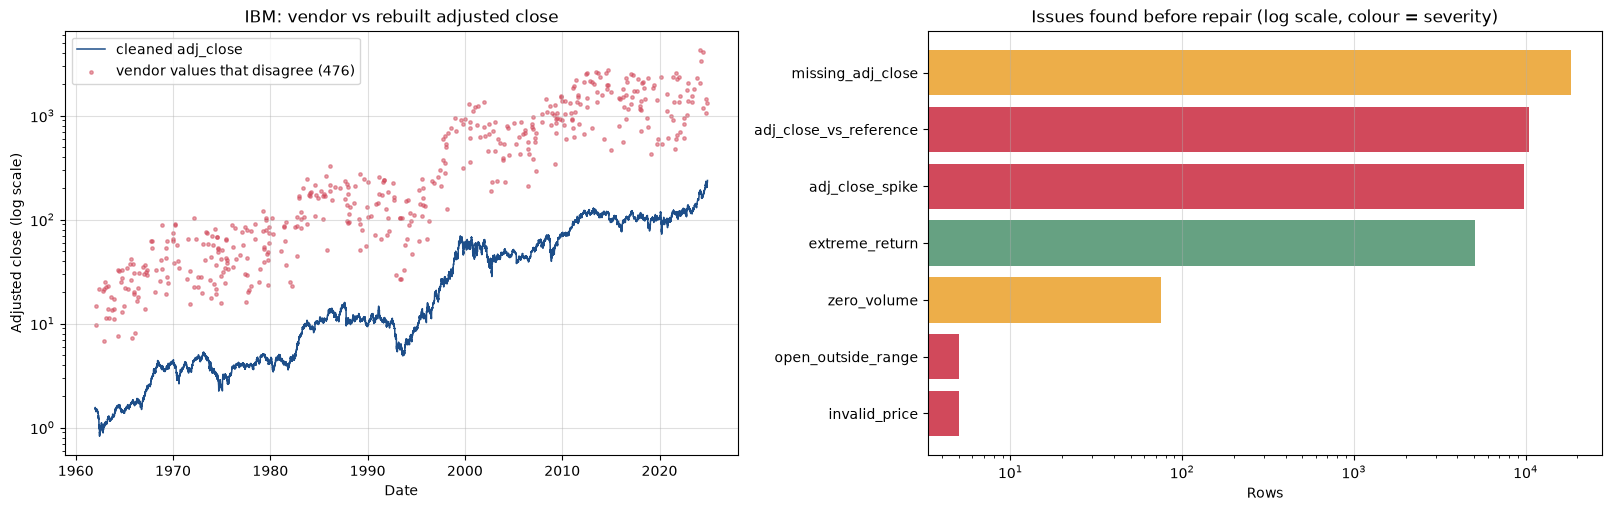

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), layout="constrained")
sample = "IBM"
vendor = unique_rows.loc[unique_rows["ticker"] == sample].assign(ts=lambda x: pd.to_datetime(x["ts"])).sort_values("ts")
fixed = cleaned.loc[cleaned["ticker"] == sample]
vendor_bad = vendor.merge(fixed[["ts", "adj_close"]].assign(ts=lambda x: pd.to_datetime(x["ts"])), on="ts", suffixes=("", "_clean"))
vendor_bad = vendor_bad[vendor_bad["adj_close"].notna() & ((vendor_bad["adj_close"] / vendor_bad["adj_close_clean"] - 1).abs() > REL_TOL)]
axes[0].plot(pd.to_datetime(fixed["ts"]), fixed["adj_close"], color="#1d4e89", lw=1.1, label="cleaned adj_close")
axes[0].scatter(vendor_bad["ts"], vendor_bad["adj_close"], s=6, color="#d1495b", alpha=0.5, label=f"vendor values that disagree ({len(vendor_bad):,})")
axes[0].set(yscale="log", title=f"{sample}: vendor vs rebuilt adjusted close", xlabel="Date", ylabel="Adjusted close (log scale)")
axes[0].legend(); axes[0].grid(True, alpha=0.4)
counts = pre_repair.groupby(["issue_type", "severity"]).size().rename("n").reset_index().sort_values("n")
palette = {"high": "#d1495b", "medium": "#edae49", "low": "#66a182"}
axes[1].barh(counts["issue_type"], counts["n"], color=counts["severity"].map(palette))
axes[1].set(xscale="log", title="Issues found before repair (log scale, colour = severity)", xlabel="Rows")
axes[1].grid(True, axis="x", alpha=0.4)
plt.show()

## Persist the results

Written to the **working copy** only; `ohlc_hw` itself is left untouched and re-verified by fingerprint. `ts` is stored as ISO `YYYY-MM-DD` text so SQL date filters work. Besides `ohlc_hw_cleaned` (with all repair flags) the database receives the quarantine, the pre-repair quality report and the ticker audit.

In [23]:
to_bool_int = lambda frame: frame.assign(**{c: frame[c].astype(int) for c in frame.columns if frame[c].dtype == bool})
klass = cleaned["extreme_return_class"].astype(object).where(cleaned["extreme_return_class"].notna(), None)
out_cleaned = cleaned.assign(ts=cleaned["ts"].dt.strftime("%Y-%m-%d"), extreme_return_class=klass)
out_cleaned = to_bool_int(out_cleaned)[["source_rowid", "ts", "ticker", *PRICE, "adj_close", "volume", "ticker_raw", *fix_cols, *flag_cols, "extreme_return_class"]]
out_quarantine = quarantine.assign(ts=pd.to_datetime(quarantine["ts"]).dt.strftime("%Y-%m-%d"))

out_cleaned.to_sql("ohlc_hw_cleaned", conn, if_exists="replace", index=False, chunksize=50_000)
out_quarantine.to_sql("ohlc_hw_quarantine", conn, if_exists="replace", index=False)
pre_repair.to_sql("ohlc_hw_quality_report", conn, if_exists="replace", index=False)
ticker_audit.to_sql("ohlc_hw_ticker_audit", conn, if_exists="replace", index=False)
conn.execute("CREATE UNIQUE INDEX IF NOT EXISTS ux_cleaned_key ON ohlc_hw_cleaned (ticker, ts)")
conn.commit()

# read back and verify what was stored, and that the source table is unchanged
stored = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned", conn)
assert len(stored) == len(cleaned) and stored["ts"].str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
assert conn.execute("SELECT COUNT(*), SUM(volume), ROUND(SUM(close), 6) FROM ohlc_hw").fetchone() == RAW_FINGERPRINT, "ohlc_hw changed!"
latest = stored.groupby("ticker")["ts"].agg(first="min", last="max", rows="size")
print("Tables in database:", [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name")])
print(f"ohlc_hw_cleaned: {len(stored):,} rows, {stored['ticker'].nunique()} tickers, {stored['ts'].min()} .. {stored['ts'].max()}")
display(latest.sort_values("last").tail(8))
conn.close()

Tables in database: ['market_caps', 'ohlc', 'ohlc_hw', 'ohlc_hw_cleaned', 'ohlc_hw_quality_report', 'ohlc_hw_quarantine', 'ohlc_hw_ticker_audit']
ohlc_hw_cleaned: 368,251 rows, 30 tickers, 1962-01-02 .. 2024-12-06


,first,last,rows
ticker,,,
AMZN,1997-05-15,2024-12-06,6937
CVX,1962-01-02,2024-12-06,15843
DIS,1962-01-02,2024-12-06,15867
IBM,1962-01-02,2024-12-06,15843
KO,1962-01-02,2024-12-06,15842
MRK,1962-01-02,2024-12-06,15842
NKE,1980-12-02,2024-12-06,11098
PG,1962-01-02,2024-12-06,15843


## Summary of decisions

* **Labels** were cleaned before anything else; the original label is kept (`ticker_raw`) with a label→ticker audit table.
* **Duplicates**: exact copies dropped; conflicting keys would be quarantined, not resolved by "keep first".
* **Missing sessions**: none relative to the reference calendar; the detector is proven on a hand-checkable example.
* **Raw OHLC** was found consistent with the reference except for `open = 0` rows, which are repaired from the same day's range and flagged.
* **adj_close** was the real dirt (missing *and* inflated values) and is rebuilt as `close × same-day reference factor` — never forward-filled and never carried across dates.
* **3σ returns** are review flags. The raw close agrees with the reference on all of them, so no value was interpolated; interpolation is reserved for *confirmed* errors and demonstrated on injected data.
* **Volume**: unknown → 0 + flag; observed zeros are kept and flagged.
* **Everything is accounted for**: raw rows = exact duplicates + quarantined + retained.

Next: `02_stock_report_template.ipynb` reads `ohlc_hw_cleaned`.